In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [61]:
data = load_breast_cancer()

In [62]:
x = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

#print(x.head())
print(x.shape)
#print(x.info())
# print(x.isnull().sum())

(569, 30)


12.418920129526722


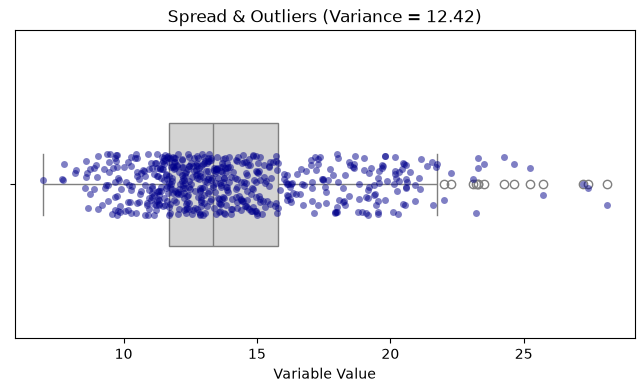

In [75]:
variance = x["mean radius"].var()  
# mean = x["mean radius"].mean()

print(variance)
# print(mean)

plt.figure(figsize=(8, 4))
sns.boxplot(x=x['mean radius'], color='lightgray', width=0.4)
sns.stripplot(x=x['mean radius'], color='darkblue', alpha=0.5, jitter=True)  # maps a numeric variable against one or more categorical variables

plt.title(f'Spread & Outliers (Variance = {x["mean radius"].var():.2f})')
plt.xlabel('Variable Value')
plt.show()

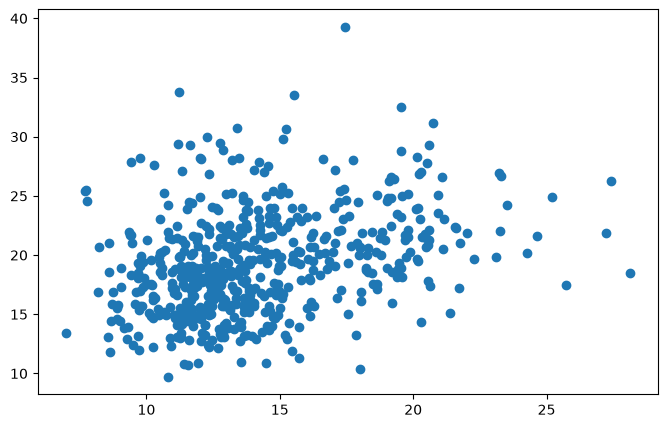

In [77]:
plt.figure(figsize=(8, 5))

# only displays the points no reg line

plt.scatter(x= x['mean radius'], y = x['mean texture'])
plt.show()

Covariance: 4.907581563992921


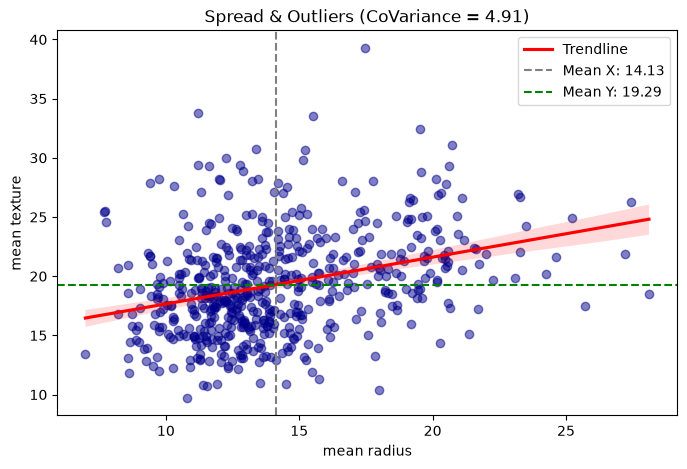

In [72]:
cov_val = x['mean radius'].cov(x['mean texture'])
print(f"Covariance: {cov_val}")

# Optional: Get the full covariance matrix for the whole dataset
# cov_matrix = x.cov(numeric_only=True)
# print(cov_matrix)

mean_x = x['mean radius'].mean()
mean_y = x['mean texture'].mean()

plt.figure(figsize=(8, 5))

# Draws scatter points + regression line automatically
sns.regplot(
    data=x, 
    x='mean radius', 
    y='mean texture', 
    scatter_kws={'color': 'darkblue', 'alpha': 0.5}, 
    line_kws={'color': 'red', 'label': 'Trendline'}
)

plt.axvline(mean_x, color='gray', linestyle='--', linewidth=1.5, label=f'Mean X: {mean_x:.2f}')
plt.axhline(mean_y, color='green', linestyle='--', linewidth=1.5, label=f'Mean Y: {mean_y:.2f}')

plt.title(f'Spread & Outliers (CoVariance = {x["mean radius"].cov(x['mean texture']):.2f})')
plt.xlabel('mean radius')
plt.ylabel("mean texture")
plt.legend()
plt.show()

In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

In [13]:
# let's retain all components to understand how much variance each captures.

pca = PCA() 

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [14]:
# what percentage of total variance each component captures
print(pca.explained_variance_ratio_) # Each value represents the variance captured by its corresponding principal component - eigen value

# higest ones will be selected

[4.44134918e-01 1.89446183e-01 9.54335633e-02 6.72468941e-02
 5.51769040e-02 3.93453424e-02 2.18176591e-02 1.58331722e-02
 1.27878330e-02 1.14544250e-02 9.26269214e-03 8.47428916e-03
 7.99746679e-03 5.30706257e-03 3.12250212e-03 2.57146110e-03
 2.03925720e-03 1.86696858e-03 1.49100638e-03 1.03671459e-03
 9.25703045e-04 8.66421035e-04 7.19778970e-04 5.88332657e-04
 5.04652748e-04 2.45507775e-04 2.16103111e-04 5.71732867e-05
 2.57352579e-05 4.27774949e-06]


In [15]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print(cumulative_variance)

[0.44413492 0.6335811  0.72901466 0.79626156 0.85143846 0.8907838
 0.91260146 0.92843464 0.94122247 0.95267689 0.96193959 0.97041388
 0.97841134 0.9837184  0.98684091 0.98941237 0.99145162 0.99331859
 0.9948096  0.99584631 0.99677202 0.99763844 0.99835822 0.99894655
 0.9994512  0.99969671 0.99991281 0.99996999 0.99999572 1.        ]


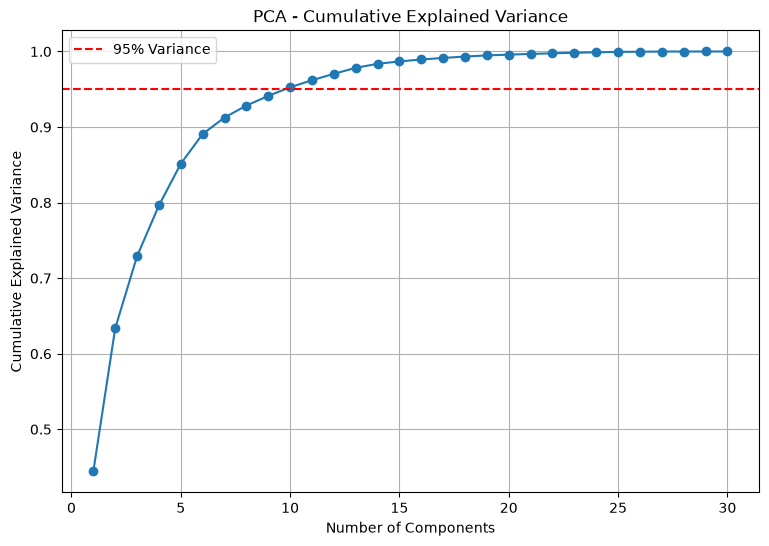

In [16]:
plt.figure(figsize=(9, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')

plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.legend()
plt.grid()
plt.show()

# We look for an elbow point, where additional components contribute considerably less variance.

In [17]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [86]:
print("Original shape:", X_train_scaled.shape)
print("Reduced shape:", X_train_pca.shape)

print("Components:", pca.n_components_)
# print("Components:", pca.components_) # how much captured by each feature (original) in the eigen vector
print(
    "Variance retained:",
    pca.explained_variance_ratio_.sum()
)

Original shape: (455, 30)
Reduced shape: (455, 10)
Components: 10
Variance retained: 0.9526768937417547


In [89]:
# See how much each original features contribute to each component
components = pd.DataFrame(
    pca.components_,
    columns=x_train.columns,
    index=[f"PC{i+1}" for i in range(len(pca.components_))]
)

# print(components)

      mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
PC1      0.217636      0.095485        0.226435   0.219862         0.148544   
PC2     -0.238698     -0.066463       -0.219569  -0.233778         0.176462   
PC3     -0.003253      0.069831       -0.004272   0.030472        -0.109980   
PC4     -0.037402      0.601827       -0.038242  -0.051231        -0.173798   
PC5      0.045752     -0.082470        0.044420   0.019193        -0.345732   
PC6      0.017565     -0.027608        0.015805  -0.010955        -0.287157   
PC7     -0.092948     -0.020767       -0.085071  -0.036567        -0.121382   
PC8      0.038815      0.136995        0.025900   0.073975        -0.288729   
PC9      0.216530     -0.163750        0.222072   0.186486         0.025386   
PC10     0.088418      0.207270        0.078271   0.089696        -0.037835   

      mean compactness  mean concavity  mean concave points  mean symmetry  \
PC1           0.242196        0.257764             0

In [87]:
print(X_train_pca[:5])  

#PCA multiplies each standardized feature (observations value) by its corresponding eigenvector coefficient and adds the results.

# all these new features / components shows the position of each observation 

[[-4.16725097  0.25551153 -0.35231281 -0.6479033  -0.64338351 -0.1062928
   0.18548548 -0.25653853 -0.4799642   0.70109682]
 [ 4.59726035 -0.96763448 -0.56021842 -0.88432999  0.03355316 -1.11887298
  -2.11987343  0.31620603  0.78668098 -0.28367188]
 [-4.56432721 -0.17149634  1.50643205 -0.71431503 -1.87013714  1.2365397
   0.23022163 -0.11700154  0.74212154 -0.30937615]
 [-0.88369256  0.43891174 -1.44909011 -1.95715912 -0.00766553  0.2561566
  -0.0926121  -0.17958336  0.08829616  0.25482191]
 [-2.95139888  0.36563266  1.18177151  0.56903982 -1.34317425  1.91139436
  -0.51146914 -0.39167359  0.24400164 -0.04940766]]


In [90]:
#  more defined results

pca_df = pd.DataFrame(
    X_train_pca,
    columns=[f"PC{i+1}" for i in range(X_train_pca.shape[1])]
)

print(pca_df.head())

        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0 -4.167251  0.255512 -0.352313 -0.647903 -0.643384 -0.106293  0.185485   
1  4.597260 -0.967634 -0.560218 -0.884330  0.033553 -1.118873 -2.119873   
2 -4.564327 -0.171496  1.506432 -0.714315 -1.870137  1.236540  0.230222   
3 -0.883693  0.438912 -1.449090 -1.957159 -0.007666  0.256157 -0.092612   
4 -2.951399  0.365633  1.181772  0.569040 -1.343174  1.911394 -0.511469   

        PC8       PC9      PC10  
0 -0.256539 -0.479964  0.701097  
1  0.316206  0.786681 -0.283672  
2 -0.117002  0.742122 -0.309376  
3 -0.179583  0.088296  0.254822  
4 -0.391674  0.244002 -0.049408  


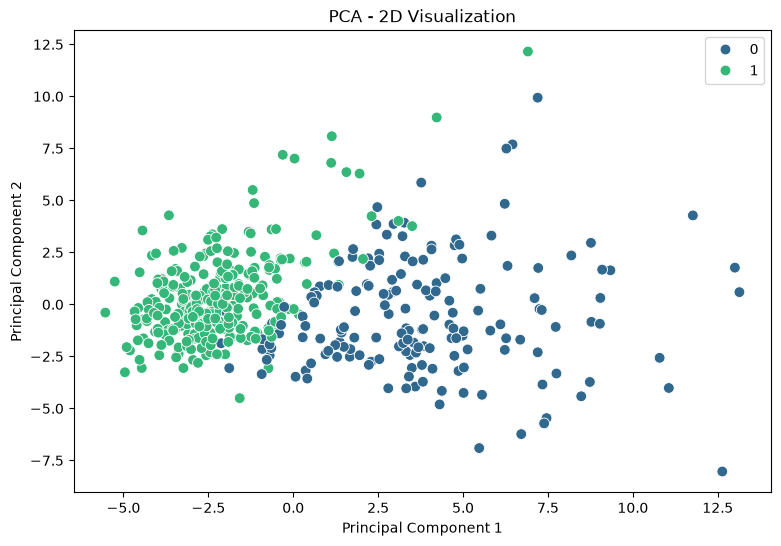

In [19]:
pca_2d = PCA(n_components=2) # let's use only two components.

X_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_2d[:, 0],
    y=X_2d[:, 1],
    hue=y_train,
    palette='viridis',
    s=60
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - 2D Visualization')

plt.show()

# This allows us to visualize how the two target classes are distributed across the first two principal components.

In [20]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 0.9736842105263158
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [91]:
results = pd.DataFrame({
    "precited" : y_pred,
    "actual" : y_test
})
print(results.head(10))

   precited  actual
0         0       0
1         1       1
2         0       0
3         1       1
4         0       0
5         1       1
6         1       1
7         0       0
8         0       0
9         0       0
